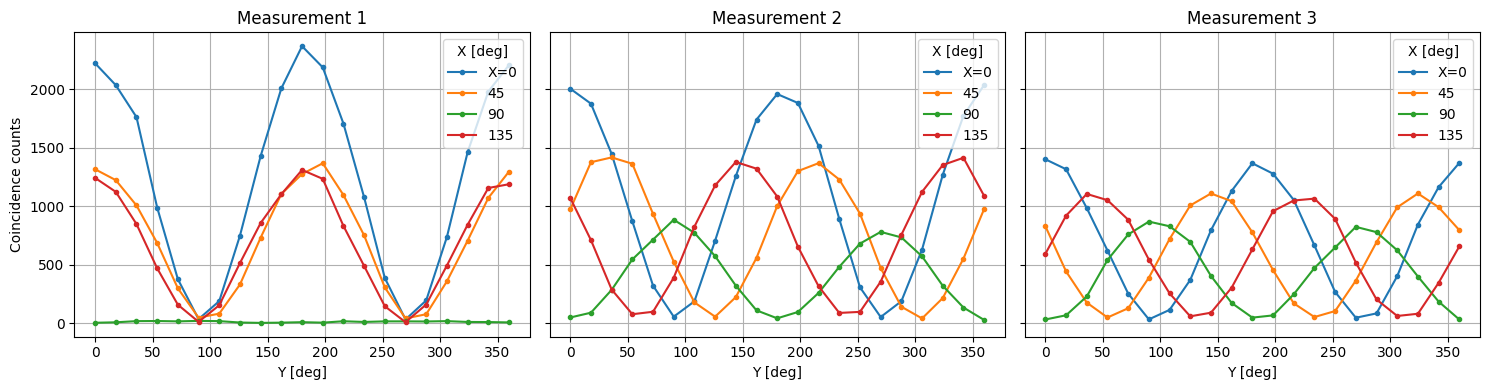

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# correlation curves

file_corcurve1 = "CHSHmeasurements/corr_meas_01.txt" # --> classical state
file_corcurve2 = "CHSHmeasurements/corr_meas_02.txt" # --> 
file_corcurve3 = "CHSHmeasurements/corr_meas_03.txt"

curve_data_1 = pd.read_csv(file_corcurve1, sep=r"\s+", skiprows=3, comment="#", names=["Y", "X=0", "45", "90", "135"])
curve_data_2 = pd.read_csv(file_corcurve2, sep=r"\s+", skiprows=3, comment="#", names=["Y", "X=0", "45", "90", "135"])
curve_data_3 = pd.read_csv(file_corcurve3, sep=r"\s+", skiprows=3, comment="#", names=["Y", "X=0", "45", "90", "135"])
#print(data)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

datasets = [curve_data_1, curve_data_2, curve_data_3]
titles = ["Measurement 1", "Measurement 2", "Measurement 3"]

for ax, data, title in zip(axes, datasets, titles):
    for column in data.columns[1:]:
        ax.plot(data["Y"], data[column], marker=".", label=column)

    ax.set_title(title)
    ax.set_xlabel("Y [deg]")
    ax.grid()
    ax.legend(title="X [deg]")

axes[0].set_ylabel("Coincidence counts")

plt.tight_layout()
plt.show()

Measurement1 - classical state |H>
Measurement2 - phi -
Measurement3 - phi +

Measurement one shows a classical state. the state prepared by the source is initially in the state |0> (X=0deg or horizontal) which can easily be seen from the curve of the orthogonal direction (V or X=90deg), which lets no light pass through, which means no coincidence photons will reach the photo-detector and thus the light must be polarized in the orthogonal direction. 
In the measurement for entangled states, we observe that the peaks and dips for X=0 and X=90 are always on the same relative angle, while the peaks ands dips for the "off-diagonals" X=45 and X=135 experience a phase shift. From this we can determine if state phi- or phi+ were created. In Measurement 2, state phi- was created, which we can see from the peak of the X=135 curve being at 135 degrees, while the X=45 curve shows a dip there (insert projection diagram) 
The coincidence count amplitudes differ somewhat for each state, which might be due to lacking coherence or simply that we optimized for that.

In [ ]:
# homemade CHSH inequality
from itertools import product

angles_A = [0, 45, 90, 135]
angles_B = [22.5, 67.5, 112.5, 157.5]

df_phiplus = pd.DataFrame(product(angles_A, angles_B), columns=["A", "B"])
df_phiminus = pd.DataFrame(product(angles_A, angles_B), columns=["A", "B"])

df_phiplus["coincidence_count"] = [3149,743,491,2933, 2759,2507,364,712, 320,2055,2063,449, 995,235,2226,2910]

df_phiminus["coincidence_count"] =[1439,382,191,1221, 259,565,1997,1779, 304,2323,2608,588, 1397,2102,769,146]


E_plus = {
    (row["A"], row["B"]): row["coincidence_count"]
    for _, row in df_phiplus.iterrows()
}
E_minus = {
    (row["A"], row["B"]): row["coincidence_count"]
    for _, row in df_phiminus.iterrows()
}

def calculate_E(E):
    E1 = (E[(0,22.5)] - E[(0,112.5)] - E[(90,22.5)] + E[(90,112.5)]) / (E[(0,22.5)] + E[(0,112.5)] + E[(90,22.5)] + E[(90,112.5)])

    E2 = (E[(45,22.5)] - E[(45,112.5)] - E[(135,22.5)] + E[(135,112.5)]) / (E[(45,22.5)] + E[(45,112.5)] + E[(135,22.5)] + E[(135,112.5)])

    E3 = (E[(0,67.5)] - E[(0,157.5)] - E[(90,67.5)] + E[(90,157.5)]) / (E[(0,67.5)] + E[(0,157.5)] + E[(90,67.5)] + E[(90,157.5)])

    E4 = (E[(45,67.5)] - E[(45,157.5)] - E[(135,67.5)] + E[(135,157.5)]) / (E[(45,67.5)] + E[(45,157.5)] + E[(135,67.5)] + E[(135,157.5)])

    return [E1, E2, E3, E4]

results = {
    "E_minus": calculate_E(E_minus),
    "E_plus": calculate_E(E_plus)
}

S_df = pd.DataFrame({
    "state": ["phi+", "phi-"],
    "S": [results["E_plus"][0] + results["E_plus"][1] - results["E_plus"][2] + results["E_plus"][3],
          results["E_minus"][0] + results["E_minus"][1] - results["E_minus"][2] + results["E_minus"][3]],
    "Sdash": [results["E_plus"][0] - results["E_plus"][1] - results["E_plus"][2] - results["E_plus"][3],
              results["E_minus"][0] - results["E_minus"][1] - results["E_minus"][2] - results["E_minus"][3]]
})

print(S_df)

  state         S     Sdash
0  phi+  2.618891  0.070986
1  phi-  0.126877  2.577643


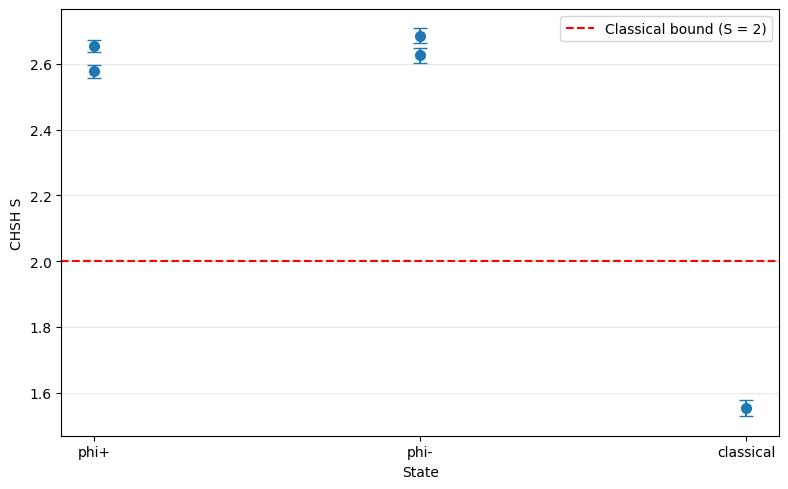

In [ ]:
from pathlib import Path
import re

""" 
The states are still wrong based on my findings from above
"""

files = [f for f in Path("CHSHmeasurements").glob("*.txt") if f.name.lower().startswith("chsh")]
data = []

for file in files:
    with open(file, "r") as f:
        header = "".join([next(f) for _ in range(7)])

    try:
        S = float(header.split("CHSH Result:")[1].split()[0])
        DeltaS = float(header.split("CHSH Error:")[1].split()[0])
        n = int(header.split("no of Stdev:")[1].split()[0])
    except (IndexError, ValueError):
        continue

    data.append({"filename": file.name, "S": S, "DeltaS": DeltaS, "n": n})

# create state column
for d in data:
    d["state"] = d["filename"].rsplit("_", 1)[-1].replace(".txt", "").strip()

#display(data)
states = [d["state"] for d in data]
S = [d["S"] for d in data]
errors = [d["DeltaS"] for d in data]

plt.figure(figsize=(8, 5))
plt.errorbar(states, S, yerr=errors, fmt='o', capsize=5, markersize=7)
plt.axhline(y=2, color="red", linestyle="--", label="Classical bound (S = 2)")

plt.xlabel("State")
plt.ylabel("CHSH S")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()